In [1]:
from popy.io_tools import load_behavior_yuri
from popy.behavior_data_tools import *

/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-s98mq5ef because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


# General Measures

1. Plot performance and behavioral measures across all sessions, comparing sham and DCZ conditions.
   - Probability of choosing the best option
   - Probability of switching
   - Reaction time across different epochs
   - Number of abandoned trials

In [2]:
behav = load_behavior_yuri()

behav['best_selection'] = behav['best_target'] == behav['target']
behav = add_switch_info(behav)
#behav = add_reaction_time(behav)
behav['abandoned'] = np.isnan(behav['target'])

behav = add_trial_in_block(behav)
#behav = add_date_of_recordig(behav)
behav = add_trials_since_switch(behav)

# add best_selection: if 'best_tartet' == 'target'

behav

/workspace/uzsombi/inserm/PoPy/popy/behavior_data_tools.py:916: UserWarning: This function is deprecated, use add_switch_info with add_trials_since_switch=True instead.
  warnings.warn("This function is deprecated, use add_switch_info with add_trials_since_switch=True instead.")


,monkey,session,trial_id,block_id,best_target,target,feedback,best_selection,switch,abandoned,trial_id_in_block,trials_since_switch
0,yu_DCZ,10,1,0,1,3,0.0,False,NaN,False,0,0
1,yu_DCZ,10,2,0,1,3,1.0,False,0.0,False,1,1
2,yu_DCZ,10,3,0,1,2,0.0,False,1.0,False,2,0
3,yu_DCZ,10,4,0,1,1,1.0,True,1.0,False,3,0
4,yu_DCZ,10,5,0,1,1,0.0,True,0.0,False,4,1
...,...,...,...,...,...,...,...,...,...,...,...,...
23410,yu_sham,71,535,12,3,3,1.0,True,0.0,False,24,3
23411,yu_sham,71,536,12,3,3,1.0,True,0.0,False,25,4
23412,yu_sham,71,537,12,3,3,1.0,True,0.0,False,26,5
23413,yu_sham,71,538,12,3,3,1.0,True,0.0,False,27,6


monkey
yu_DCZ     20
yu_sham    22
Name: n_sessions, dtype: int64
n_trials: Sham mean=555.6, DCZ mean=559.6, Welch t=-0.4292, p=0.6701
best_selection: Sham mean=0.7681, DCZ mean=0.7576, Welch t=0.6327, p=0.5306
switch: Sham mean=0.1464, DCZ mean=0.1444, Welch t=0.1836, p=0.8555
trials_since_switch: Sham mean=11.64, DCZ mean=10.66, Welch t=1.521, p=0.1365


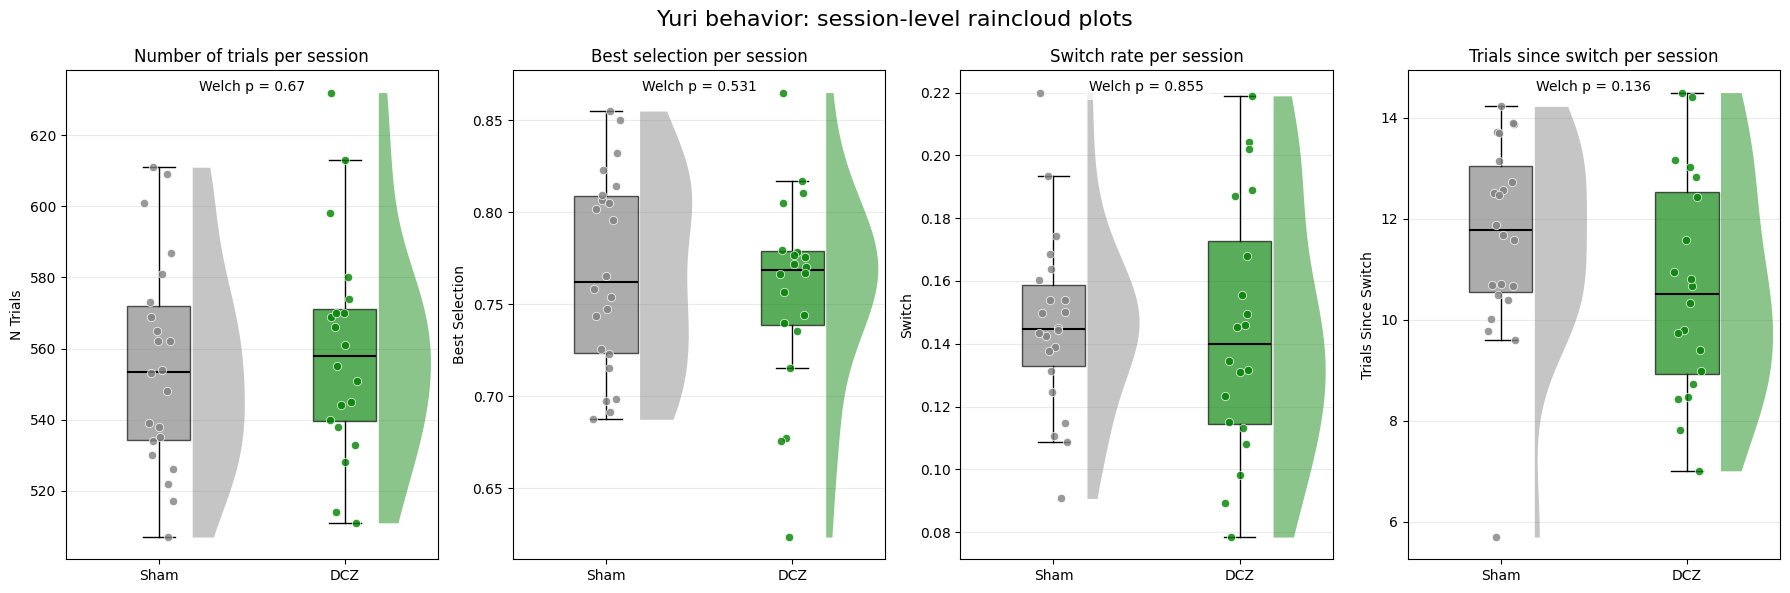

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde, ttest_ind

conditions = {
    'yu_sham': {'label': 'Sham', 'color': 'grey'},
    'yu_DCZ': {'label': 'DCZ', 'color': 'green'},
}

session_summary = (
    behav[behav['monkey'].isin(conditions)]
    .groupby(['monkey', 'session'], as_index=False)
    .agg(
        n_trials=('session', 'size'),
        best_selection=('best_selection', 'mean'),
        switch=('switch', 'mean'),
        trials_since_switch=('trials_since_switch', 'mean'),
    )
)

session_counts = session_summary.groupby('monkey')['session'].nunique()
print(session_counts.rename('n_sessions'))

plot_specs = [
    ('n_trials', 'Number of trials per session'),
    ('best_selection', 'Best selection per session'),
    ('switch', 'Switch rate per session'),
    ('trials_since_switch', 'Trials since switch per session'),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 6))
rng = np.random.default_rng(7)

for axis, (measure, title) in zip(axes, plot_specs):
    values_by_condition = {}
    for monkey in conditions:
        values_by_condition[monkey] = session_summary.loc[
            session_summary['monkey'] == monkey, measure
        ].dropna().to_numpy()

    sham_values = values_by_condition['yu_sham']
    dcz_values = values_by_condition['yu_DCZ']
    test_result = ttest_ind(sham_values, dcz_values, equal_var=False)
    print(
        f'{measure}: Sham mean={sham_values.mean():.4g}, '
        f'DCZ mean={dcz_values.mean():.4g}, '
        f'Welch t={test_result.statistic:.4g}, p={test_result.pvalue:.4g}'
    )

    for condition_index, (monkey, condition) in enumerate(conditions.items()):
        values = values_by_condition[monkey]
        mean = values.mean()

        jitter = rng.uniform(-0.08, 0.08, size=len(values))
        axis.scatter(
            condition_index + jitter,
            values,
            color=condition['color'],
            edgecolor='white',
            linewidth=0.6,
            alpha=0.8,
            zorder=3,
        )
        axis.boxplot(
            values,
            positions=[condition_index],
            widths=0.34,
            patch_artist=True,
            showfliers=False,
            boxprops={'facecolor': condition['color'], 'alpha': 0.65},
            medianprops={'color': 'black', 'linewidth': 1.5},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            zorder=2,
        )

        distribution_y = np.linspace(values.min(), values.max(), 200)
        if len(values) > 1 and np.ptp(values) > 0:
            density = gaussian_kde(values)(distribution_y)
            density = density / density.max() * 0.28
        else:
            spread = max(abs(mean) * 0.03, 0.05)
            density = np.exp(-0.5 * ((distribution_y - mean) / spread) ** 2) * 0.28

        axis.fill_betweenx(
            distribution_y,
            condition_index + 0.18,
            condition_index + 0.18 + density,
            color=condition['color'],
            alpha=0.45,
            linewidth=0,
            zorder=1,
        )

    axis.set_title(title)
    axis.set_xticks(range(len(conditions)), [condition['label'] for condition in conditions.values()])
    axis.set_ylabel(measure.replace('_', ' ').title())
    axis.text(
        0.5,
        0.98,
        f'Welch p = {test_result.pvalue:.3g}',
        transform=axis.transAxes,
        ha='center',
        va='top',
        fontsize=10,
        bbox={'facecolor': 'white', 'alpha': 0.75, 'edgecolor': 'none'},
    )
    axis.grid(axis='y', alpha=0.25)
    axis.set_axisbelow(True)

fig.suptitle('Yuri behavior: session-level raincloud plots', fontsize=16)
fig.tight_layout()
plt.show()

- History weight (CPD)
   - GLM with multiple factors

In [ ]:
behav = add_history_of_feedback(behav, num_trials=6, one_column=False, add_history_of_targets=False)

behav

,monkey,session,trial_id,block_id,best_target,target,feedback,best_selection,switch,abandoned,...,R_3,R_4,R_5,R_6,T_1,T_2,T_3,T_4,T_5,T_6
0,yu_DCZ,10,1,0,1,3,0.0,False,NaN,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,yu_DCZ,10,2,0,1,3,1.0,False,0.0,False,...,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN
2,yu_DCZ,10,3,0,1,2,0.0,False,1.0,False,...,NaN,NaN,NaN,NaN,3.0,3.0,NaN,NaN,NaN,NaN
3,yu_DCZ,10,4,0,1,1,1.0,True,1.0,False,...,0.0,NaN,NaN,NaN,2.0,3.0,3.0,NaN,NaN,NaN
4,yu_DCZ,10,5,0,1,1,0.0,True,0.0,False,...,1.0,0.0,NaN,NaN,1.0,2.0,3.0,3.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23410,yu_sham,71,535,12,3,3,1.0,True,0.0,False,...,1.0,0.0,0.0,0.0,3.0,3.0,3.0,1.0,2.0,3.0
23411,yu_sham,71,536,12,3,3,1.0,True,0.0,False,...,1.0,1.0,0.0,0.0,3.0,3.0,3.0,3.0,1.0,2.0
23412,yu_sham,71,537,12,3,3,1.0,True,0.0,False,...,1.0,1.0,1.0,0.0,3.0,3.0,3.0,3.0,3.0,1.0
23413,yu_sham,71,538,12,3,3,1.0,True,0.0,False,...,1.0,1.0,1.0,1.0,3.0,3.0,3.0,3.0,3.0,3.0


Pooled GLM coefficients:


,Sham,DCZ
R_1,-3.611444,-3.404530
R_2,-1.813261,-1.588059
R_3,-0.808757,-0.678985
R_4,-0.408004,-0.191599
R_5,-0.164552,0.060618
R_6,-0.006504,0.041767


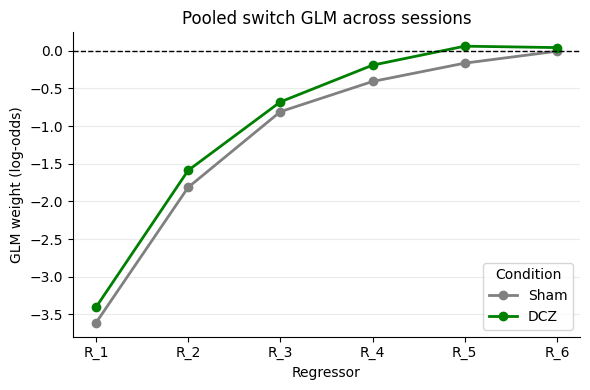

Per-session GLMs fitted: 42
Welch t-tests: Sham vs DCZ for each regressor


,regressor,sham_mean,dcz_mean,t_statistic,p_value
0,R_1,-3.954361,-3.610940,-1.590014,0.120737
1,R_2,-1.967172,-1.699660,-1.891338,0.067380
2,R_3,-0.893012,-0.742625,-1.288359,0.205416
3,R_4,-0.445478,-0.205327,-2.331919,0.024835
4,R_5,-0.148212,0.070963,-1.775866,0.083713
5,R_6,0.007617,0.053481,-0.366436,0.716015


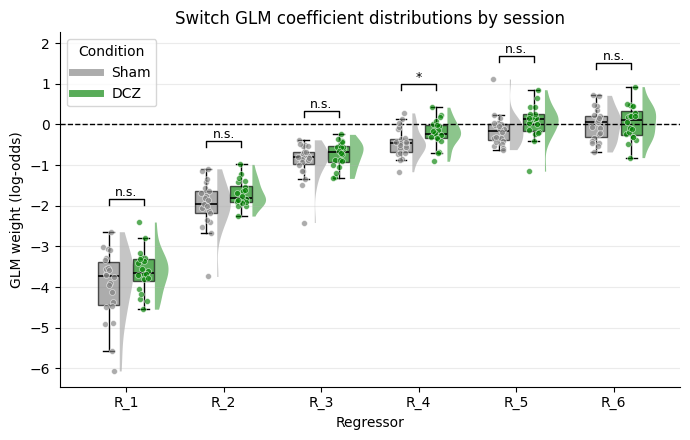

In [13]:
import statsmodels.api as sm
from scipy.stats import ttest_ind

regressors = [f'R_{index}' for index in range(1, 7)]
glm_data = behav[behav['monkey'].isin(conditions)].copy()
glm_data = glm_data.dropna(subset=['switch', *regressors])


def fit_switch_glm(data):
    design_matrix = sm.add_constant(data[regressors], has_constant='add')
    return sm.GLM(data['switch'], design_matrix, family=sm.families.Binomial()).fit()


# Fit one GLM per monkey using all available sessions together.
pooled_results = {
    monkey: fit_switch_glm(glm_data[glm_data['monkey'] == monkey])
    for monkey in conditions
}

pooled_weights = pd.DataFrame({
    conditions[monkey]['label']: result.params[regressors]
    for monkey, result in pooled_results.items()
})
print('Pooled GLM coefficients:')
display(pooled_weights)

fig, axis = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(regressors))
for monkey, condition in conditions.items():
    axis.plot(
        x_positions,
        pooled_weights[condition['label']],
        marker='o',
        linewidth=2,
        color=condition['color'],
        label=condition['label'],
    )
axis.axhline(0, color='black', linewidth=1, linestyle='--')
axis.set_xticks(x_positions, regressors)
axis.set_xlabel('Regressor')
axis.set_ylabel('GLM weight (log-odds)')
axis.set_title('Pooled switch GLM across sessions')
axis.legend(title='Condition')
axis.grid(axis='y', alpha=0.25)
sns.despine(ax=axis)
fig.tight_layout()
plt.show()


# Fit one GLM per session.
session_results = []
for (monkey, session), session_data in glm_data.groupby(['monkey', 'session']):
    if session_data['switch'].nunique() < 2:
        continue
    try:
        result = fit_switch_glm(session_data)
    except (np.linalg.LinAlgError, ValueError):
        continue
    session_results.append({
        'monkey': monkey,
        'session': session,
        **result.params[regressors].to_dict(),
    })

session_weights = pd.DataFrame(session_results)
print(f'Per-session GLMs fitted: {len(session_weights)}')

# Compare Sham and DCZ coefficients separately for each regressor.
condition_comparison_results = []
for regressor in regressors:
    sham_values = session_weights.loc[
        session_weights['monkey'] == 'yu_sham', regressor
    ].dropna()
    dcz_values = session_weights.loc[
        session_weights['monkey'] == 'yu_DCZ', regressor
    ].dropna()
    test_result = ttest_ind(sham_values, dcz_values, equal_var=False)
    condition_comparison_results.append({
        'regressor': regressor,
        'sham_mean': sham_values.mean(),
        'dcz_mean': dcz_values.mean(),
        't_statistic': test_result.statistic,
        'p_value': test_result.pvalue,
    })

print('Welch t-tests: Sham vs DCZ for each regressor')
display(pd.DataFrame(condition_comparison_results))


# Show the coefficient distribution across sessions for each condition.
fig, axis = plt.subplots(figsize=(7, 4.5))
rng = np.random.default_rng(7)
condition_offsets = {'yu_sham': -0.18, 'yu_DCZ': 0.18}

for regressor_index, regressor in enumerate(regressors):
    for monkey, condition in conditions.items():
        values = session_weights.loc[
            session_weights['monkey'] == monkey, regressor
        ].dropna().to_numpy()
        distribution_x = regressor_index + condition_offsets[monkey]

        jitter = rng.uniform(-0.055, 0.055, size=len(values))
        axis.scatter(
            distribution_x + jitter,
            values,
            color=condition['color'],
            edgecolor='white',
            linewidth=0.5,
            alpha=0.65,
            s=18,
            zorder=3,
        )
        axis.boxplot(
            values,
            positions=[distribution_x],
            widths=0.22,
            patch_artist=True,
            showfliers=False,
            boxprops={'facecolor': condition['color'], 'alpha': 0.65},
            medianprops={'color': 'black', 'linewidth': 1.2},
            whiskerprops={'color': 'black'},
            capprops={'color': 'black'},
            zorder=2,
        )

        distribution_y = np.linspace(values.min(), values.max(), 200)
        if len(values) > 1 and np.ptp(values) > 0:
            density = gaussian_kde(values)(distribution_y)
            density = density / density.max() * 0.14
        else:
            spread = max(abs(values.mean()) * 0.03, 0.05)
            density = np.exp(-0.5 * ((distribution_y - values.mean()) / spread) ** 2) * 0.14

        axis.fill_betweenx(
            distribution_y,
            distribution_x + 0.11,
            distribution_x + 0.11 + density,
            color=condition['color'],
            alpha=0.45,
            linewidth=0,
            zorder=1,
        )

# Add Sham-versus-DCZ significance brackets above each regressor pair.
plot_range = session_weights[regressors].to_numpy().ptp()
if plot_range == 0:
    plot_range = 1
bar_height = 0.06 * plot_range
bar_cap = 0.02 * plot_range
max_bar_height = -np.inf
for regressor_index, comparison in enumerate(condition_comparison_results):
    sham_values = session_weights.loc[
        session_weights['monkey'] == 'yu_sham', comparison['regressor']
    ].dropna()
    dcz_values = session_weights.loc[
        session_weights['monkey'] == 'yu_DCZ', comparison['regressor']
    ].dropna()
    bar_y = max(sham_values.max(), dcz_values.max()) + bar_height
    left_x = regressor_index + condition_offsets['yu_sham']
    right_x = regressor_index + condition_offsets['yu_DCZ']
    axis.plot(
        [left_x, left_x, right_x, right_x],
        [bar_y, bar_y + bar_cap, bar_y + bar_cap, bar_y],
        color='black',
        linewidth=1,
        zorder=4,
    )
    p_value = comparison['p_value']
    significance = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'n.s.'
    axis.text(
        (left_x + right_x) / 2,
        bar_y + bar_cap,
        significance,
        ha='center',
        va='bottom',
        fontsize=9,
        zorder=5,
    )
    max_bar_height = max(max_bar_height, bar_y + bar_cap)

axis.set_ylim(top=max_bar_height + 0.08 * plot_range)
axis.axhline(0, color='black', linewidth=1, linestyle='--')
axis.set_xticks(x_positions, regressors)
axis.set_xlabel('Regressor')
axis.set_ylabel('GLM weight (log-odds)')
axis.set_title('Switch GLM coefficient distributions by session')
axis.plot([], [], color=conditions['yu_sham']['color'], linewidth=5, alpha=0.65, label='Sham')
axis.plot([], [], color=conditions['yu_DCZ']['color'], linewidth=5, alpha=0.65, label='DCZ')
axis.legend(title='Condition')
axis.grid(axis='y', alpha=0.25)
sns.despine(ax=axis)
fig.tight_layout()
plt.show()